In [5]:
from dataclasses import dataclass, field
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ml.data_io import iter_signals_and_targets, iter_signals_only
from ml.features import add_epoch_drift, build_feature_df

In [7]:
@dataclass
class Config:  # noqa: D101
    bundle_dir: Path = Path("../data")
    sf: int = 100  # sampling rate
    samples_per_epoch: int = 30 * 100  # 30s epochs
    stage_names: list[str] = field(default_factory=lambda: ["Wake", "N1", "N2", "N3", "REM"])
    # Feature params
    load_precomputed_features: bool = False
    bands: dict[str, tuple[float, float]] = field(
        default_factory=lambda: {
            "slow_delta": (0.5, 2),
            "delta": (2, 4),
            "theta": (4, 8),
            "alpha": (8, 12),
            "sigma": (12, 15),
            "beta": (15, 30),
        },
    )
    add_epoch_drift_window: int = 2
    add_epoch_drift_symmetric: bool = True
    # model params
    num_classes: int = 5
    eta: float = 0.03
    max_depth: int = 10
    subsample: float = 0.8
    colsample_bytree: float = 0.8
    num_boost_round: int = 500
    seed: int = 42
    smoothing_window: int = 1
    n_jobs: int = 4
    # decoding
    decoder: str = "hmm"  # options: "argmax", "smooth", "hmm"
    hmm_alpha: float = 1.0
    # cross-validation params
    cv_n_splits: int = 5
    # choose whether to create submission predictions
    create_submission: bool = False
    submission_name: str = "submission.csv"


config = Config(
    load_precomputed_features=False,
    create_submission=False,
    submission_name="aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa.csv",
    seed=0
)

# -----------------------
# Load data and build feature DataFrames
# -----------------------
print("Loading raw data...")
raw_train_data = iter_signals_and_targets(config.bundle_dir, split="train")
raw_test_data = iter_signals_only(config.bundle_dir, split="test")
if config.load_precomputed_features:
    print("Loading precomputed feature DataFrames...")
    df_train = pd.read_csv("features/train_features.csv")
else:
    print("Building feature DataFrame for training data...")
    df_train = build_feature_df(raw_train_data, with_labels=True, config=config)
    df_train = add_epoch_drift(
        df_train,
        window=config.add_epoch_drift_window,
        symmetric=config.add_epoch_drift_symmetric,
    )

X = df_train.drop(columns=["label", "identifier", "patient_id", "epoch_idx"])
y = df_train["label"]
groups = df_train["patient_id"].to_numpy()

Loading raw data...
Building feature DataFrame for training data...


In [8]:
def plot_feature_density(
    X, y, feature_name,
    q_low=0.005, q_high=0.995,
    fill=True
):
    """
    Plot KDE of one feature per class with robust x-limits.

    The x-axis is clipped so that (q_high - q_low)*100 % of
    each class distribution is visible.

    Parameters
    ----------
    X : pd.DataFrame
    y : array-like
    feature_name : str
    q_low, q_high : float
        Quantiles for x-limits (default = 99%)
    fill : bool
    """
    if feature_name not in X.columns:
        raise ValueError(f"Feature '{feature_name}' not found")

    df = X.copy()
    df["label"] = y

    # --- compute robust x-limits per class
    qmins, qmaxs = [], []
    for label, g in df.groupby("label"):
        vals = g[feature_name].dropna()
        qmins.append(vals.quantile(q_low))
        qmaxs.append(vals.quantile(q_high))

    xmin = min(qmins)
    xmax = max(qmaxs)

    # --- plot
    plt.figure(figsize=(7, 4))
    sns.kdeplot(
        data=df,
        x=feature_name,
        hue="label",
        fill=fill,
        alpha=0.5,
        common_norm=False,
        clip=(xmin, xmax),
        linewidth=4
    )

    plt.xlim(xmin, xmax)
    plt.xlabel(feature_name)
    plt.ylabel("Density")
    plt.title(f"Density of {feature_name}")
    plt.tight_layout()
    plt.show()

In [9]:
X.columns

Index(['mean', 'std', 'ptp', 'slow_delta', 'delta', 'theta', 'alpha', 'sigma',
       'beta', 'rel_slow_delta', 'rel_delta', 'rel_theta', 'rel_alpha',
       'rel_sigma', 'rel_beta', 'hjorth_activity', 'hjorth_mobility',
       'hjorth_complexity', 'sef50', 'sef95', 'spectral_flatness', 'zcr',
       'line_length', 'rms', 'kurtosis', 'sigma_env_mean', 'sigma_env_std',
       'sigma_burst_frac', 'spec_entropy', 'log_delta_theta', 'log_alpha_beta',
       'theta_dominance', 'beta_silence', 'epoch_drift_prev',
       'epoch_drift_next', 'epoch_drift_mean'],
      dtype='object')

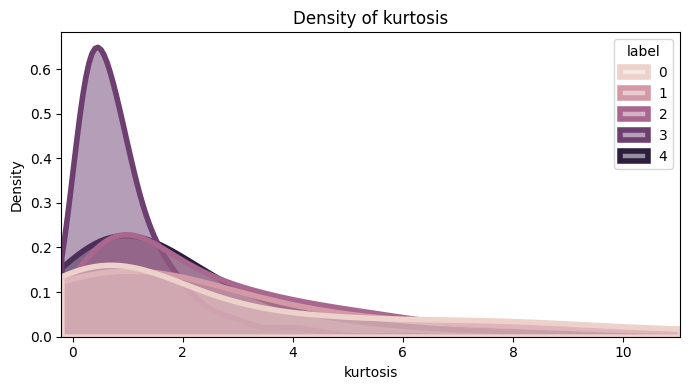

In [10]:
plot_feature_density(X, y, "kurtosis", q_high=0.9)